## **DATA ANALYTICS PYTHON PROJECT--BLINKIT ANALYSIS**

#### **Import Libraries**

In [367]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#### **Import Raw Data**

In [368]:
import pandas as pd

In [369]:
df = pd.read_excel("C:/Users/admin/Downloads/BlinkIT Grocery Data.xlsx")

#### **Sample Data**

In [370]:
df.head()

,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
0,Regular,FDX32,Fruits and Vegetables,2012,OUT049,Tier 1,Medium,Supermarket Type1,0.100014,15.10,145.4786,5.0
1,Low Fat,NCB42,Health and Hygiene,2022,OUT018,Tier 3,Medium,Supermarket Type2,0.008596,11.80,115.3492,5.0
2,Regular,FDR28,Frozen Foods,2016,OUT046,Tier 1,Small,Supermarket Type1,0.025896,13.85,165.0210,5.0
3,Regular,FDL50,Canned,2014,OUT013,Tier 3,High,Supermarket Type1,0.042278,12.15,126.5046,5.0
4,Low Fat,DRI25,Soft Drinks,2015,OUT045,Tier 2,Small,Supermarket Type1,0.033970,19.60,55.1614,5.0


In [371]:
df.tail(15)

,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
8508,Regular,FDU57,Snack Foods,2018,OUT027,Tier 3,Medium,Supermarket Type3,0.089121,NaN,149.8708,4.0
8509,Regular,FDU58,Snack Foods,2018,OUT027,Tier 3,Medium,Supermarket Type3,0.028871,NaN,188.7898,4.0
8510,Regular,FDX46,Snack Foods,2018,OUT027,Tier 3,Medium,Supermarket Type3,0.057835,NaN,57.5562,4.0
8511,Regular,FDX57,Snack Foods,2018,OUT027,Tier 3,Medium,Supermarket Type3,0.047037,NaN,96.4068,4.0
8512,Regular,FDY33,Snack Foods,2018,OUT027,Tier 3,Medium,Supermarket Type3,0.096730,NaN,159.0262,4.0
8513,Regular,DRY23,Soft Drinks,2018,OUT027,Tier 3,Medium,Supermarket Type3,0.108568,NaN,42.9112,4.0
8514,low fat,FDA11,Baking Goods,2018,OUT027,Tier 3,Medium,Supermarket Type3,0.043029,NaN,94.7436,4.0
8515,low fat,FDK38,Canned,2018,OUT027,Tier 3,Medium,Supermarket Type3,0.053032,NaN,149.1734,4.0
8516,low fat,FDO38,Canned,2018,OUT027,Tier 3,Medium,Supermarket Type3,0.072486,NaN,78.9986,4.0
8517,low fat,FDG32,Fruits and Vegetables,2018,OUT027,Tier 3,Medium,Supermarket Type3,0.175143,NaN,222.3772,4.0


#### **Size Of Data**

In [372]:
 print("Size of Data:",df.shape)

Size of Data: (8523, 12)


#### **Field Data**

In [373]:
df.columns

Index(['Item Fat Content', 'Item Identifier', 'Item Type',
       'Outlet Establishment Year', 'Outlet Identifier',
       'Outlet Location Type', 'Outlet Size', 'Outlet Type', 'Item Visibility',
       'Item Weight', 'Sales', 'Rating'],
      dtype='object')

#### **Data Types**

In [374]:
df.dtypes

Item Fat Content              object
Item Identifier               object
Item Type                     object
Outlet Establishment Year      int64
Outlet Identifier             object
Outlet Location Type          object
Outlet Size                   object
Outlet Type                   object
Item Visibility              float64
Item Weight                  float64
Sales                        float64
Rating                       float64
dtype: object

#### **Data Cleaning**

In [375]:
print(df['Item Fat Content'].unique())

['Regular' 'Low Fat' 'low fat' 'LF' 'reg']


In [376]:
df['Item Fat Content'] = df['Item Fat Content'].replace({'LF':'Low Fat','low fat':'Low Fat','reg':'Regular'})

In [377]:
print(df['Item Fat Content'].unique())

['Regular' 'Low Fat']


### **BUSINESS REQUIREMENTS**

#### **KPI`S REQUIREMENTS**

In [378]:
# Total Sales
total_sales = df['Sales'].sum()

# Average Sales
avg_sales = df['Sales'].mean()

# Number of Items Sold
no_of_item_sold = df['Sales'].count()

# Average Ratings
avg_ratings = df['Rating'].mean()

# Display Results
print(f"Total Sales: ${total_sales:,.0f}")
print(f"Average Sales: ${avg_sales:,.0f}")
print(f"Number of Items Sold: {no_of_item_sold:,}")
print(f"Average Rating: {avg_ratings:.1f}")


Total Sales: $1,201,681
Average Sales: $141
Number of Items Sold: 8,523
Average Rating: 4.0


#### **CHARTS REQUIREMENTS**

##### **Total Sales By Fat Content**

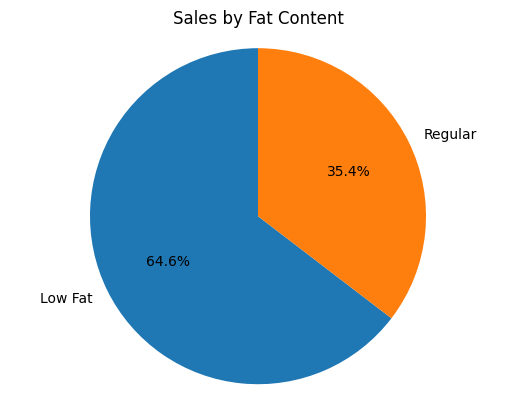

In [379]:
sales_by_fat = df.groupby('Item Fat Content')['Sales'].sum()

plt.pie(sales_by_fat,labels=sales_by_fat.index,
                    autopct='%.1f%%',
                    startangle=90)

plt.title('Sales by Fat Content')
plt.axis('equal')
plt.show()

##### **Total Sales By Iteam Type**

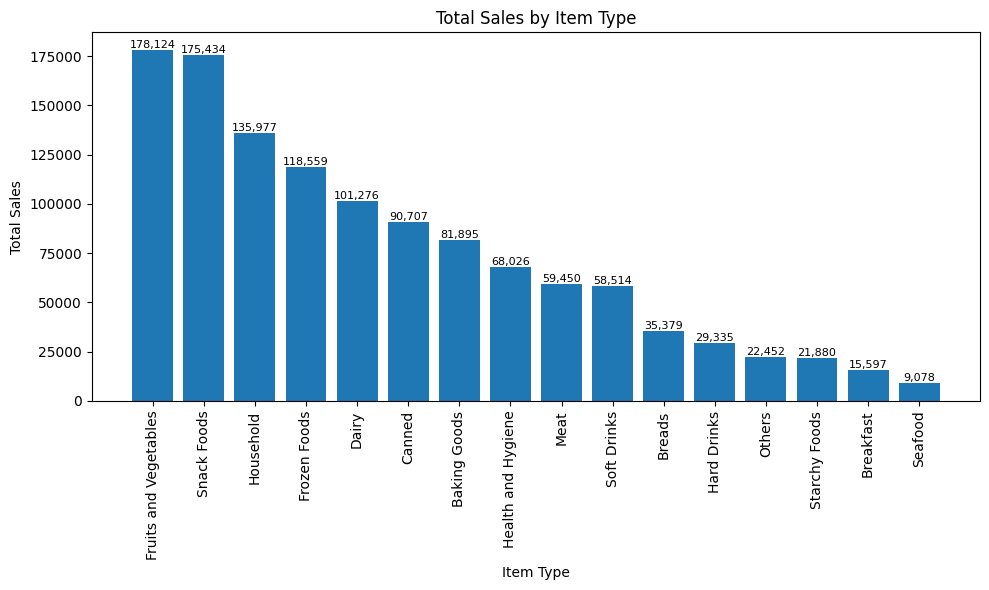

In [380]:
sales_by_item = df.groupby('Item Type')['Sales'].sum().sort_values(ascending=False)

plt.figure(figsize=(10, 6))

bars = plt.bar(sales_by_item.index, sales_by_item.values)

plt.title('Total Sales by Item Type')
plt.xlabel('Item Type')
plt.ylabel('Total Sales')
plt.xticks(rotation=90)

# Add sales values on top of each bar
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{bar.get_height():,.0f}',
        ha='center',
        va='bottom',
        fontsize=8
    )

plt.tight_layout()
plt.show()



##### **Fat content by outer for Total Sales**

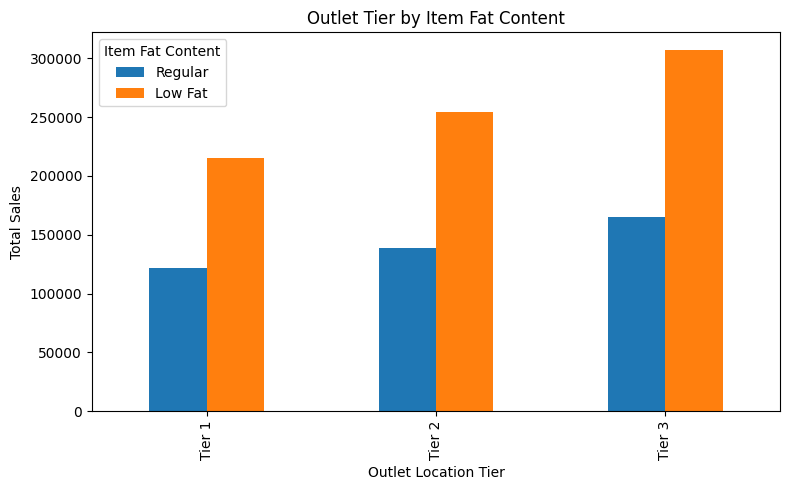

In [381]:
grouped = df.groupby(['Outlet Location Type', 'Item Fat Content'])['Sales'].sum().unstack()
grouped = grouped[['Regular', 'Low Fat']]

ax = grouped.plot(
    kind='bar',
    figsize=(8, 5),
    title='Outlet Tier by Item Fat Content'
)

plt.xlabel('Outlet Location Tier')
plt.ylabel('Total Sales')
plt.legend(title='Item Fat Content')
plt.tight_layout()
plt.show()

#### **Total Sales by Outlet Establishment**

In [382]:
print("DataFrame columns:")
print(df.columns.tolist())



DataFrame columns:
['Item Fat Content', 'Item Identifier', 'Item Type', 'Outlet Establishment Year', 'Outlet Identifier', 'Outlet Location Type', 'Outlet Size', 'Outlet Type', 'Item Visibility', 'Item Weight', 'Sales', 'Rating']


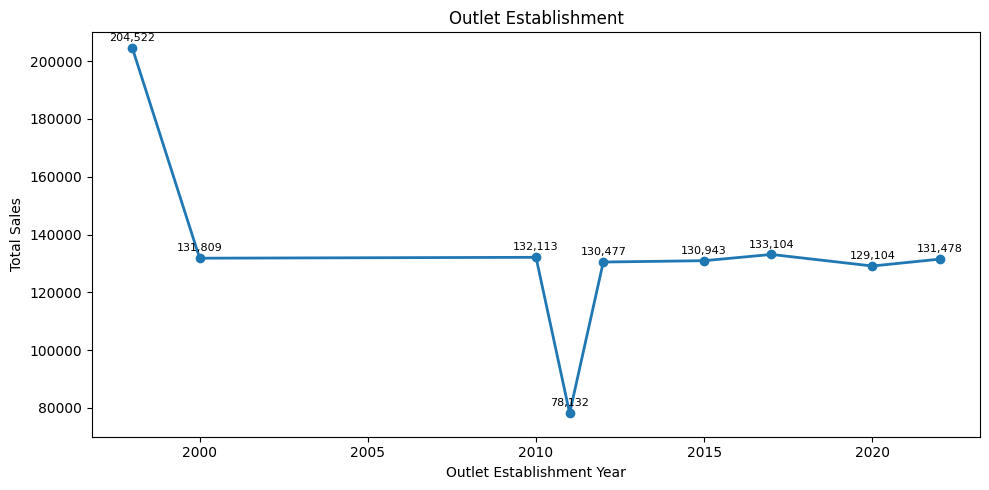

In [383]:

import matplotlib.pyplot as plt

# Data from the reference graph
years = [1998, 2000, 2010, 2011, 2012, 2015, 2017, 2020, 2022]
sales = [204522, 131809, 132113, 78132, 130477,
         130943, 133104, 129104, 131478]

plt.figure(figsize=(10, 5))

plt.plot(years, sales, marker='o', linewidth=2)

# Display values above each point
for x, y in zip(years, sales):
    plt.annotate(f'{y:,}', (x, y),
                 textcoords="offset points",
                 xytext=(0, 5),
                 ha='center', fontsize=8)

plt.title('Outlet Establishment')
plt.xlabel('Outlet Establishment Year')
plt.ylabel('Total Sales')

plt.ylim(70000, 210000)
plt.xticks([2000, 2005, 2010, 2015, 2020])

plt.tight_layout()
plt.show()


#### **Sales by Outlet Size**

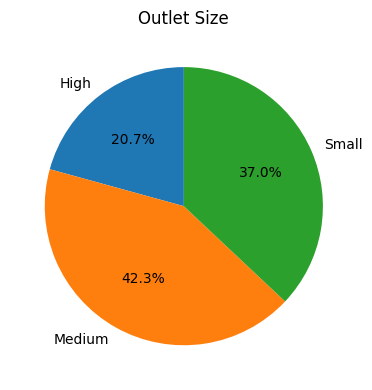

In [384]:
sales_by_size = df.groupby('Outlet Size')['Sales'].sum()

plt.figure(figsize=(4, 4))
plt.pie(sales_by_size, labels=sales_by_size.index, autopct='%1.1f%%', startangle=90)
plt.title('Outlet Size')
plt.tight_layout()
plt.show()


#### **Sales by Outlet Location**

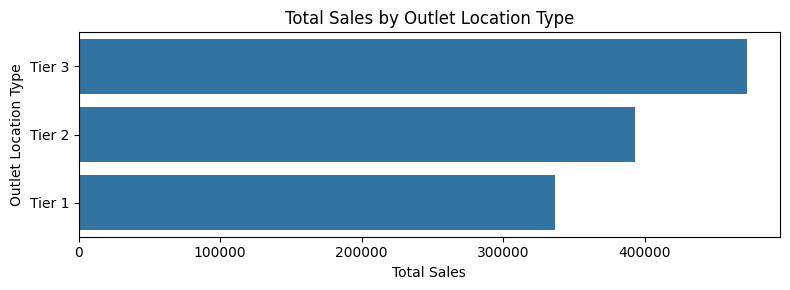

In [385]:




# Sales by Outlet Location

sales_by_location = df.groupby('Outlet Location Type')['Sales'].sum().reset_index()

# Sort sales in descending order
sales_by_location = sales_by_location.sort_values(
    'Sales', ascending=False
)

# Create graph
plt.figure(figsize=(8, 3))

ax = sns.barplot(
    x='Sales',
    y='Outlet Location Type',
    data=sales_by_location
)

# Graph title and labels
plt.title('Total Sales by Outlet Location Type')
plt.xlabel('Total Sales')
plt.ylabel('Outlet Location Type')

# Adjust layout
plt.tight_layout()

# Display graph
plt.show()

